In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('turkish_names.txt', 'r', encoding='utf-8').read().splitlines()
words[:10]

['gürçağ',
 'oray',
 'safvet',
 'aygüzel',
 'güvenç',
 'cennethan',
 'sehergül',
 'etike',
 'elem',
 'zişan']

In [3]:
chars= sorted(list(set(''.join(words))))
stoi= {s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos= {i:s for s,i in stoi.items()}

In [4]:
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'r', 18: 's', 19: 't', 20: 'u', 21: 'v', 22: 'y', 23: 'z', 24: 'ç', 25: 'ö', 26: 'ü', 27: 'ğ', 28: 'ı', 29: 'ş', 0: '.'}


In [5]:
block_size=3
X, Y=[],[]
for w in words:

  context=[0]*block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '-->', itos[ix])
    context = context [1:] + [ix]

X=torch.tensor(X)
Y=torch.tensor(Y)

In [6]:
X

tensor([[ 0,  0,  0],
        [ 0,  0,  7],
        [ 0,  7, 26],
        ...,
        [ 3,  9,  8],
        [ 9,  8,  1],
        [ 8,  1, 14]])

In [7]:
C = torch.rand((30,2))
C

tensor([[0.7631, 0.7460],
        [0.5024, 0.0380],
        [0.1804, 0.2844],
        [0.9111, 0.9898],
        [0.9406, 0.2843],
        [0.3878, 0.2461],
        [0.2911, 0.3900],
        [0.5804, 0.6612],
        [0.3344, 0.4169],
        [0.3551, 0.3056],
        [0.2774, 0.9410],
        [0.6740, 0.2564],
        [0.3551, 0.7722],
        [0.1017, 0.2514],
        [0.2298, 0.2362],
        [0.7357, 0.5614],
        [0.7221, 0.1839],
        [0.4802, 0.3775],
        [0.1400, 0.4046],
        [0.5655, 0.3725],
        [0.1429, 0.1567],
        [0.2296, 0.3913],
        [0.6516, 0.0439],
        [0.5648, 0.1831],
        [0.6405, 0.2483],
        [0.6020, 0.4373],
        [0.7721, 0.7893],
        [0.7219, 0.4555],
        [0.9577, 0.6526],
        [0.6527, 0.5698]])

In [8]:
emb = C[X]
emb.shape

torch.Size([72308, 3, 2])

In [9]:
W1 = torch.randn((6,100))
b1 = torch.randn(100)

In [10]:
torch.cat([emb[:,0,:],emb[:,1,:],emb[:,2,:]],1).shape

torch.Size([72308, 6])

In [11]:
torch.cat(torch.unbind(emb,1),1).shape #it is the same tensor with previous one

torch.Size([72308, 6])

In [12]:
h = torch.tanh(emb.view(-1 , 6) @ W1+b1 )

In [13]:
h

tensor([[-0.9592,  0.0507,  0.9864,  ...,  0.8937, -0.9691, -0.9181],
        [-0.9698,  0.3911,  0.9858,  ...,  0.9097, -0.9543, -0.8896],
        [-0.9362,  0.1117,  0.9876,  ...,  0.9249, -0.9467, -0.8989],
        ...,
        [-0.9795,  0.7374,  0.9924,  ...,  0.9770, -0.8511, -0.9225],
        [-0.9874,  0.5492,  0.9640,  ...,  0.9504, -0.5234, -0.8056],
        [-0.9907,  0.7753,  0.9776,  ...,  0.9131, -0.0125, -0.9496]])

In [14]:
W2 = torch.randn((100,30))
b2=torch.randn(30)

In [15]:
logits= h @ W2 + b2
logits.shape

torch.Size([72308, 30])

In [16]:
counts = logits.exp()

In [17]:
prob=counts/counts.sum(1, keepdims=True) #every sum or row of prob is 1

In [18]:
loss= -prob[torch.arange(Y.shape[0]), Y].log().mean()
loss

tensor(26.2375)

clean version

In [19]:
#dataset
def build_dataset(words):
  block_size=3
  X, Y=[],[]
  for w in words:

    context=[0]*block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context [1:] + [ix]

  X=torch.tensor(X)
  Y=torch.tensor(Y)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1=int(0.8*len(words))
n2=int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

In [20]:
Xtr.shape, Ytr.shape

(torch.Size([57901, 3]), torch.Size([57901]))

In [21]:
g= torch.Generator().manual_seed(2147483647)
C = torch.randn((30,10), generator=g)
W1 = torch.randn((30,200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200,30), generator=g)
b2 = torch.randn(30, generator=g)
parameters = [C, W1, b1, W2, b2]

In [22]:
sum(p.nelement() for p in parameters)

12530

In [23]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre

In [24]:
for p in parameters:
  p.requires_grad=True

In [25]:
lri=[]
lossi=[]
stepi=[]


In [26]:

for i in range(50000):

  ix= torch.randint(0, Xtr.shape[0], (32,))
  # forward
  emb = C[Xtr[ix]]
  h= torch.tanh(emb.view(-1,30) @ W1 + b1)
  logits= h @ W2 + b2
  #counts = logits.exp()
  #prob=counts/counts.sum(1, keepdims=True)
  #loss= -prob[torch.arange(32), Y].log().mean()
  loss= F.cross_entropy(logits, Ytr[ix])
  #print (loss.item())
  # backward
  for p in parameters:
    p.grad=None
  loss.backward()

  lr= 0.1
  for p in parameters:
    p.data += -lr* p.grad

  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

print(loss.item())

2.1006925106048584


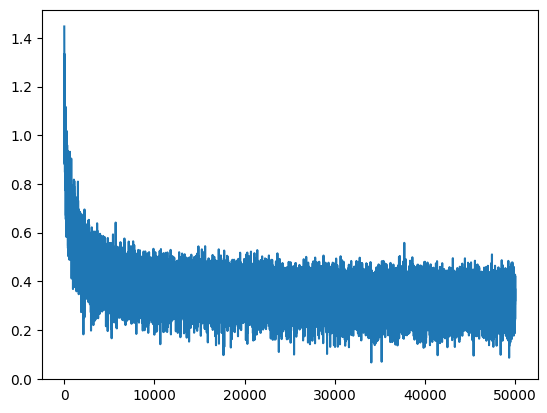

In [27]:
plt.plot(stepi, lossi)

In [28]:
torch.randint(0, X.shape[0], (32,))

tensor([30407, 11129, 62724,  1037,  5204, 61315, 39818, 16860, 56092, 62020,
        70052, 61073, 41214,  9427, 33016, 60098, 71506, 41323,  4381, 24501,
        32705, 35497, 13121, 29125, 30013, 66073, 71560, 62633, 29825, 57430,
        43470,  9095])

In [29]:
emb = C[Xdev]
h= torch.tanh(emb.view(-1,30) @ W1 + b1)
logits= h @ W2 + b2
loss= F.cross_entropy(logits, Ydev)
print(loss.item())

2.213240623474121


In [30]:
emb = C[Xtr]
h= torch.tanh(emb.view(-1,30) @ W1 + b1)
logits= h @ W2 + b2
loss= F.cross_entropy(logits, Ytr)
print(loss.item())

2.0951156616210938


validation and training loss is nearly same -- the model doesnt overfit

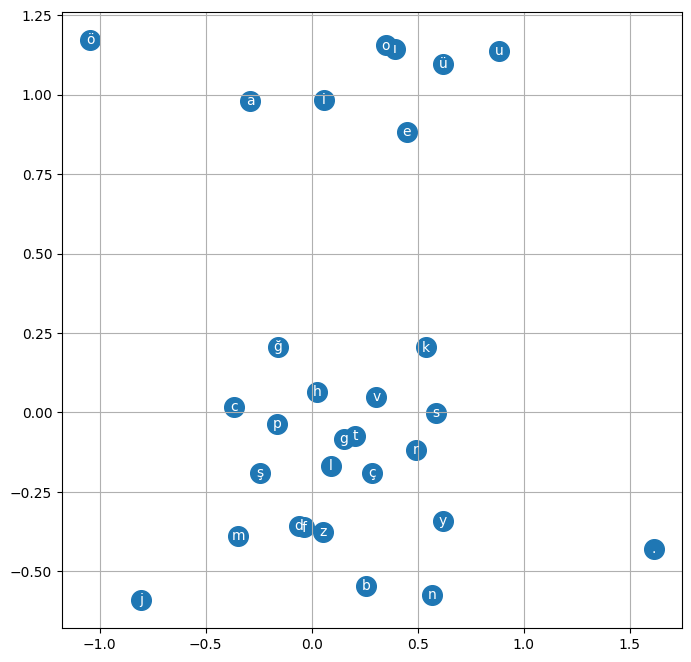

In [31]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
  plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")
plt.grid('minor')

In [32]:
g=torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
  out=[]
  context=[0]* block_size
  while True:
    emb=C[torch.tensor([context])]
    h=torch.tanh(emb.view(1,-1)@W1+b1)
    logits=h@W2+b2
    probs= F.softmax(logits, dim=1)
    ix= torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
    context=context[1:]+[ix]
    out.append(ix)
    if ix==0:
      break
  print(''.join(itos[i] for i in out))

nelgüsülfe.
kozeltop.
akayguncer.
say.
serhayar.
abdulevi.
hava.
dohalit.
ser.
meher.
zahan.
asan.
aslıcan.
güz.
zunke.
sadses.
sulcuna.
isen.
güls.
zeydilet.
